# Exploratory_data_analysis_supermarket_data

## Libraries

In [7]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
sns.set(color_codes=True)
print(os.getcwd())

/workspaces/data_analytics/Week_04


## Daten einlesen

In [8]:
df = pd.read_csv("supermarkets_data_enriched.csv")
df.head()

,Unnamed: 0,type,id,lat,lon,brand,shop,addr:city,addr:housenumber,addr:postcode,geometry,index_right,bfs_name,bfs_number,pop,pop_dens,frg_pct,emp
0,0,node,33126515,47.155616,9.037915,Spar,supermarket,NaN,NaN,NaN,POINT (9.0379152 47.1556157),227,Schänis,3315,3876,97.142857,13.054696,1408.0
1,1,node,280130028,47.155492,9.039666,ALDI,supermarket,Schänis,3,8718.0,POINT (9.0396663 47.1554921),227,Schänis,3315,3876,97.142857,13.054696,1408.0
2,2,node,6122906632,47.158959,9.044477,Denner,supermarket,Schänis,14,8718.0,POINT (9.0444769 47.1589589),227,Schänis,3315,3876,97.142857,13.054696,1408.0
3,3,node,9019298862,47.155185,9.038472,Lidl,supermarket,NaN,NaN,NaN,POINT (9.0384722 47.1551854),227,Schänis,3315,3876,97.142857,13.054696,1408.0
4,4,node,36726161,47.226191,8.980329,Migros,supermarket,Uznach,25,8730.0,POINT (8.9803292 47.2261912),1217,Uznach,3339,6489,860.610080,27.862537,3500.0


## Anzahl pro Marke

In [9]:
df['brand'].value_counts()

brand
Coop                                     497
Migros                                   495
Denner                                   423
Volg                                     210
ALDI                                      72
Spar                                      63
Lidl                                      58
Aldi                                      52
VOI Migros Partner                        44
Landi                                     39
Alnatura                                  15
Migros-Outlet                             12
VOI                                        8
Pam                                        4
Crai                                       2
Globus                                     2
Jumbo                                      2
gazi                                       1
Lidl Schweiz                               1
ZWIBOL                                     1
Eurospar                                   1
Proxi                                      1
Denn

## Balkendiagramm

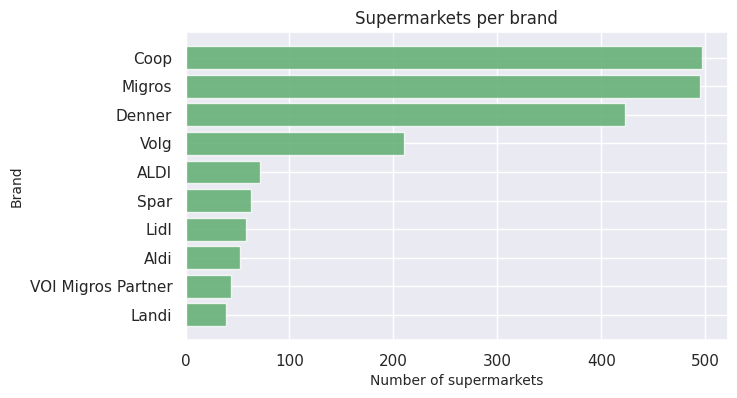

In [10]:
df_bar = df['brand'].value_counts().nlargest(10).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(7,4))
ax.barh(df_bar.index, df_bar.values, color='g', alpha=0.8)
ax.set_xlabel('Number of supermarkets', fontsize=10)
ax.set_ylabel('Brand', fontsize=10)
ax.set_title('Supermarkets per brand', fontsize=12)
plt.show()

## Streudiagrammmatrix

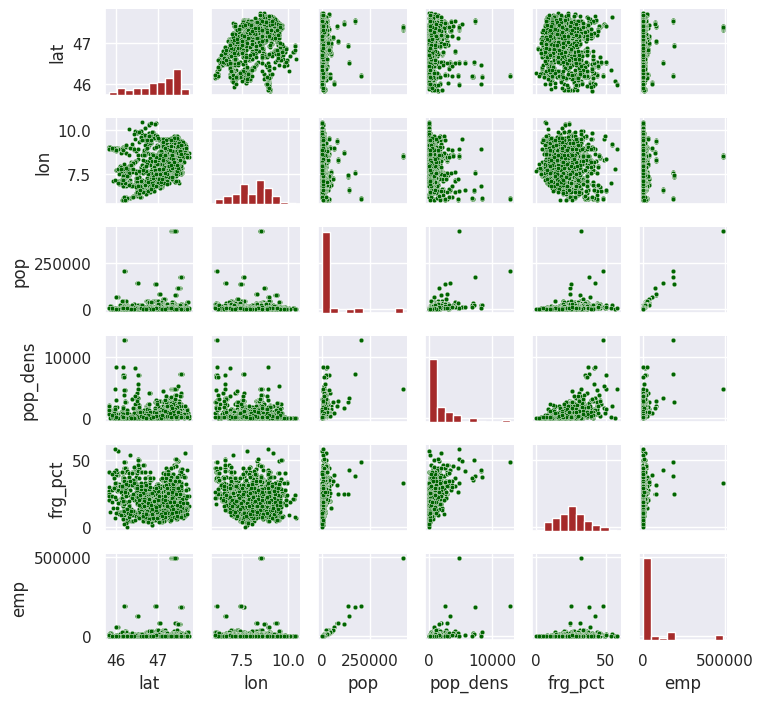

In [11]:
g = sns.PairGrid(df[['lat', 'lon', 'pop', 'pop_dens', 'frg_pct', 'emp']],
                 height=1.2, aspect=1)
g.map_upper(sns.scatterplot, color='darkgreen', s=10)
g.map_lower(sns.scatterplot, color='darkgreen', s=10)
g.map_diag(plt.hist, color='brown')

## Standorte nach Marke

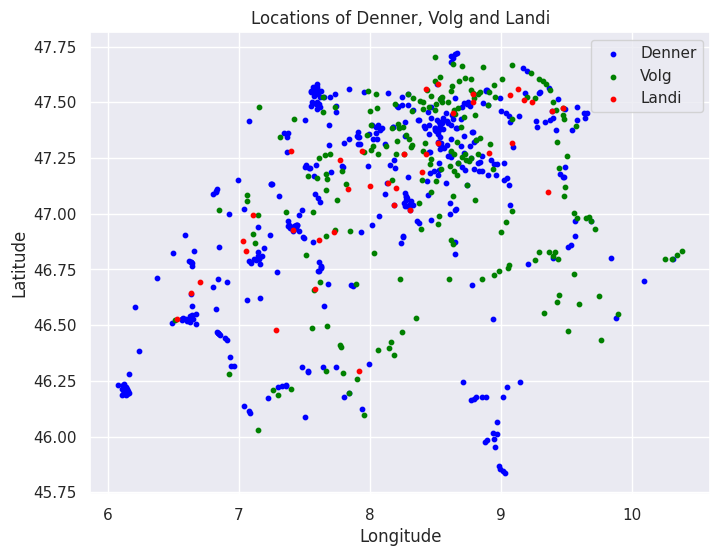

In [12]:
plt.figure(figsize=(8,6))
colors = {'Denner': 'blue', 'Volg': 'green', 'Landi': 'red'}

for brand, color in colors.items():
    sub = df[df['brand'] == brand]
    plt.scatter(sub['lon'], sub['lat'], s=10, color=color, label=brand)

plt.title('Locations of Denner, Volg and Landi', fontsize=12)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend()
plt.show()